# 08 — MobileNetV2 Object Detection: Training and Evaluation

**Project:** Privacy-Preserving Edge AI Framework for Intelligent Transportation  
**Dataset:** India Driving Dataset (IDD Detection)  
**Model:** MobileNetV2-based object detector  
**Task:** Multi-class object detection with bounding boxes  
**Evaluation:** Annotated validation split  
**Outputs:** Model checkpoint, training history, validation metrics, prediction visualizations and experiment report

This notebook uses the existing IDD dataset and the same train/validation split used for the YOLO experiments. It is intended to provide a lightweight detection baseline for edge deployment.

Important: MobileNetV2 is a feature-extraction backbone, not a complete object detector by itself. This notebook will use a detection head on top of MobileNetV2 features. Classification accuracy alone will not be used as a substitute for detection mAP.

In [1]:
# CELL 2: Imports and project paths

from pathlib import Path
import json
import shutil
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

PROJECT = Path("/workspace/ITS_Project")
ROOT = Path("/workspace/IDD_Detection")
DATA_YAML = PROJECT / "configs" / "dataset.yaml"
YOLO_DATA = PROJECT / "prepared_dataset"

CHECKPOINT_DIR = PROJECT / "checkpoints" / "mobilenetv2"
RESULT_DIR = PROJECT / "results" / "training" / "mobilenetv2"
PREDICTION_DIR = PROJECT / "results" / "predictions" / "mobilenetv2"

for folder in [CHECKPOINT_DIR, RESULT_DIR, PREDICTION_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

BEST_MODEL = CHECKPOINT_DIR / "best.pt"
LAST_MODEL = CHECKPOINT_DIR / "last.pt"

print("PyTorch:", torch.__version__)
print("Torchvision MobileNetV2 imports successful.")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.5.1+cu121
Torchvision MobileNetV2 imports successful.
CUDA available: True
GPU: NVIDIA H100 80GB HBM3 MIG 3g.40gb


In [2]:
# CELL 3: Load class names and verify dataset folders

assert ROOT.is_dir(), f"IDD dataset directory not found: {ROOT}"
assert YOLO_DATA.is_dir(), f"Prepared dataset not found: {YOLO_DATA}"
assert DATA_YAML.is_file(), f"Dataset YAML not found: {DATA_YAML}"

import yaml

with open(DATA_YAML, "r") as f:
    DATA_CONFIG = yaml.safe_load(f)

CLASS_NAMES = DATA_CONFIG["names"]

if isinstance(CLASS_NAMES, list):
    CLASS_NAMES = {i: name for i, name in enumerate(CLASS_NAMES)}
else:
    CLASS_NAMES = {int(i): name for i, name in CLASS_NAMES.items()}

NUM_CLASSES = len(CLASS_NAMES)

print("Number of classes:", NUM_CLASSES)
print("Classes:", CLASS_NAMES)

for split, expected in [("train", 31569), ("val", 10225)]:
    image_dir = YOLO_DATA / "images" / split
    label_dir = YOLO_DATA / "labels" / split

    image_stems = {p.stem for p in image_dir.glob("*.jpg")}
    label_stems = {p.stem for p in label_dir.glob("*.txt")}

    print(
        f"{split}: images={len(image_stems):,}, "
        f"labels={len(label_stems):,}, "
        f"missing labels={len(image_stems - label_stems)}, "
        f"orphan labels={len(label_stems - image_stems)}"
    )

    assert len(image_stems) == expected, f"Unexpected {split} image count"
    assert image_stems == label_stems, f"Image/label mismatch in {split}"

print("Dataset folders verified.")

Number of classes: 15
Classes: {0: 'animal', 1: 'autorickshaw', 2: 'bicycle', 3: 'bus', 4: 'car', 5: 'caravan', 6: 'motorcycle', 7: 'person', 8: 'rider', 9: 'traffic light', 10: 'traffic sign', 11: 'trailer', 12: 'train', 13: 'truck', 14: 'vehicle fallback'}
train: images=31,569, labels=31,569, missing labels=0, orphan labels=0
val: images=10,225, labels=10,225, missing labels=0, orphan labels=0
Dataset folders verified.


In [17]:
# CELL 4: Set reproducibility and training configuration

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMG_SIZE = 320
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 1e-4
NUM_WORKERS = 8

TRAIN_IMAGE_DIR = YOLO_DATA / "images" / "train"
TRAIN_LABEL_DIR = YOLO_DATA / "labels" / "train"
VAL_IMAGE_DIR = YOLO_DATA / "images" / "val"
VAL_LABEL_DIR = YOLO_DATA / "labels" / "val"

print("Device:", DEVICE)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)

Device: cuda
Image size: 320
Batch size: 32
Epochs: 20
Learning rate: 0.0001


In [18]:
# CELL 5: Define image transformations and inspect sample data

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

sample_images = sorted(TRAIN_IMAGE_DIR.glob("*.jpg"))[:5]

print("Sample training images:")
for path in sample_images:
    print(path.name, f"({Image.open(path).size[0]} × {Image.open(path).size[1]})")

assert sample_images, "No training images found."

print("\nTransforms ready.")
print("Next: build the detection dataset and MobileNetV2 detection head.")

Sample training images:
frontFar__BLR-2018-03-22_17-39-26_2_frontFar__0000060.jpg (1280 × 964)
frontFar__BLR-2018-03-22_17-39-26_2_frontFar__000006_r.jpg (1280 × 964)
frontFar__BLR-2018-03-22_17-39-26_2_frontFar__0000240.jpg (1280 × 964)
frontFar__BLR-2018-03-22_17-39-26_2_frontFar__0000420.jpg (1280 × 964)
frontFar__BLR-2018-03-22_17-39-26_2_frontFar__0000480.jpg (1280 × 964)

Transforms ready.
Next: build the detection dataset and MobileNetV2 detection head.


In [5]:
# CELL 6: Dataset loader for YOLO-format bounding-box labels

class IDDDetectionDataset(Dataset):
    def __init__(self, image_dir, label_dir, transform=None):
        self.image_dir = Path(image_dir)
        self.label_dir = Path(label_dir)
        self.transform = transform

        self.images = sorted(self.image_dir.glob("*.jpg"))
        self.label_paths = [self.label_dir / f"{p.stem}.txt" for p in self.images]

        if not self.images:
            raise RuntimeError(f"No images found in {self.image_dir}")

        missing = [p.name for p in self.label_paths if not p.is_file()]
        if missing:
            raise RuntimeError(f"Missing labels; examples: {missing[:5]}")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image_path = self.images[index]
        label_path = self.label_paths[index]

        image = Image.open(image_path).convert("RGB")
        original_width, original_height = image.size

        boxes = []
        labels = []

        content = label_path.read_text().strip()
        if content:
            for line in content.splitlines():
                values = line.split()
                if len(values) != 5:
                    continue

                class_id, xc, yc, w, h = map(float, values)
                labels.append(int(class_id))

                # Convert normalized YOLO boxes to pixel-coordinate xyxy boxes.
                x1 = (xc - w / 2) * original_width
                y1 = (yc - h / 2) * original_height
                x2 = (xc + w / 2) * original_width
                y2 = (yc + h / 2) * original_height

                boxes.append([x1, y1, x2, y2])

        if self.transform:
            image = self.transform(image)

        target = {
            "boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.tensor(labels, dtype=torch.int64),
            "image_id": torch.tensor([index]),
            "original_size": torch.tensor([original_height, original_width]),
        }

        return image, target

In [6]:
# CELL 7: Create training and validation DataLoaders

def detection_collate_fn(batch):
    images, targets = zip(*batch)
    return torch.stack(images, dim=0), list(targets)

train_dataset = IDDDetectionDataset(
    TRAIN_IMAGE_DIR,
    TRAIN_LABEL_DIR,
    transform=train_transform,
)

val_dataset = IDDDetectionDataset(
    VAL_IMAGE_DIR,
    VAL_LABEL_DIR,
    transform=val_transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    collate_fn=detection_collate_fn,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    collate_fn=detection_collate_fn,
)

print(f"Training images: {len(train_dataset):,}")
print(f"Validation images: {len(val_dataset):,}")
print(f"Training batches per epoch: {len(train_loader):,}")
print(f"Validation batches: {len(val_loader):,}")

Training images: 31,569
Validation images: 10,225
Training batches per epoch: 987
Validation batches: 320


In [7]:
# CELL 8: Inspect one batch before model training

images_batch, targets_batch = next(iter(train_loader))

print("Image batch shape:", tuple(images_batch.shape))
print("Images in batch:", len(targets_batch))

for i, target in enumerate(targets_batch[:5]):
    print(
        f"Image {i}: boxes={len(target['boxes'])}, "
        f"labels={target['labels'].tolist()[:10]}"
    )

assert images_batch.shape[1:] == (3, IMG_SIZE, IMG_SIZE)
assert all(target["boxes"].ndim == 2 for target in targets_batch)

print("Batch and target structures verified.")

Image batch shape: (32, 3, 320, 320)
Images in batch: 32
Image 0: boxes=11, labels=[0, 7, 7, 7, 7, 7, 7, 7, 6, 7]
Image 1: boxes=8, labels=[4, 8, 6, 10, 10, 4, 8, 4]
Image 2: boxes=33, labels=[3, 3, 4, 1, 3, 14, 4, 3, 4, 6]
Image 3: boxes=17, labels=[6, 8, 6, 8, 7, 7, 14, 6, 1, 7]
Image 4: boxes=3, labels=[1, 6, 8]
Batch and target structures verified.


In [8]:
# CELL 9: Initialize pretrained MobileNetV2 feature extractor

mobilenet = mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)

# Retain the convolutional feature extractor; remove classification layers.
backbone = mobilenet.features

# Freeze early layers initially for stable transfer learning.
for parameter in backbone.parameters():
    parameter.requires_grad = False

# Allow the final feature blocks to adapt to the IDD domain.
for parameter in backbone[-3:].parameters():
    parameter.requires_grad = True

backbone = backbone.to(DEVICE)
backbone.eval()

with torch.no_grad():
    sample_features = backbone(images_batch[:2].to(DEVICE))

print("Backbone output shape:", tuple(sample_features.shape))
print("Feature channels:", sample_features.shape[1])
print("MobileNetV2 backbone loaded successfully.")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth
100%|██████████| 13.6M/13.6M [00:00<00:00, 52.3MB/s]


Backbone output shape: (2, 1280, 10, 10)
Feature channels: 1280
MobileNetV2 backbone loaded successfully.


In [9]:
# CELL 10: Define a lightweight grid-based detection model

class MobileNetV2GridDetector(nn.Module):
    def __init__(self, num_classes, grid_size=10):
        super().__init__()
        self.num_classes = num_classes
        self.grid_size = grid_size

        self.backbone = mobilenet_v2(
            weights=MobileNet_V2_Weights.DEFAULT
        ).features

        # Feature map -> grid predictions:
        # [objectness, x, y, width, height, class scores]
        self.head = nn.Sequential(
            nn.Conv2d(1280, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 5 + num_classes, kernel_size=1),
            nn.AdaptiveAvgPool2d((grid_size, grid_size)),
        )

    def forward(self, images):
        features = self.backbone(images)
        predictions = self.head(features)
        return predictions.permute(0, 2, 3, 1).contiguous()


detector = MobileNetV2GridDetector(
    num_classes=NUM_CLASSES,
    grid_size=10,
).to(DEVICE)

with torch.no_grad():
    test_output = detector(images_batch[:2].to(DEVICE))

print("Detector output shape:", tuple(test_output.shape))
print("Expected shape: (batch, 10, 10, 5 + number_of_classes)")
print("Trainable parameters:", sum(p.numel() for p in detector.parameters() if p.requires_grad))
print("Model initialized.")

Detector output shape: (2, 10, 10, 20)
Expected shape: (batch, 10, 10, 5 + number_of_classes)
Trainable parameters: 5178388
Model initialized.


In [10]:
# CELL 11: Encode bounding boxes into grid targets and define the loss

import torch.nn.functional as F
from tqdm.auto import tqdm

GRID_SIZE = detector.grid_size
PRED_CHANNELS = 5 + NUM_CLASSES

def encode_grid_target(target, grid_size=GRID_SIZE):
    """
    Target format per grid cell:
    [objectness, x_offset, y_offset, box_width, box_height, class_id]
    A cell can represent one object in this experimental detector.
    """
    grid = torch.zeros(grid_size, grid_size, 6, dtype=torch.float32)

    boxes = target["boxes"]
    labels = target["labels"]
    height, width = target["original_size"].tolist()

    for box, class_id in zip(boxes, labels):
        x1, y1, x2, y2 = box.tolist()

        xc = ((x1 + x2) / 2) / width
        yc = ((y1 + y2) / 2) / height
        bw = (x2 - x1) / width
        bh = (y2 - y1) / height

        if not (0 <= class_id < NUM_CLASSES):
            continue

        gx = min(int(xc * grid_size), grid_size - 1)
        gy = min(int(yc * grid_size), grid_size - 1)

        # Keep the larger object if multiple objects share one grid cell.
        old_area = grid[gy, gx, 3] * grid[gy, gx, 4]
        new_area = bw * bh

        if grid[gy, gx, 0] == 0 or new_area > old_area:
            grid[gy, gx, 0] = 1.0
            grid[gy, gx, 1] = xc * grid_size - gx
            grid[gy, gx, 2] = yc * grid_size - gy
            grid[gy, gx, 3] = bw
            grid[gy, gx, 4] = bh
            grid[gy, gx, 5] = int(class_id)

    return grid


def detection_loss(predictions, targets):
    device = predictions.device
    batch_size = predictions.shape[0]

    encoded = torch.stack([
        encode_grid_target(target) for target in targets
    ]).to(device)

    object_mask = encoded[..., 0] == 1
    no_object_mask = ~object_mask

    obj_logits = predictions[..., 0]
    box_predictions = torch.sigmoid(predictions[..., 1:5])
    class_logits = predictions[..., 5:]

    obj_loss = F.binary_cross_entropy_with_logits(
        obj_logits, encoded[..., 0]
    )

    # Penalize background confidence, with a lower weight.
    if no_object_mask.any():
        background_loss = F.binary_cross_entropy_with_logits(
            obj_logits[no_object_mask],
            torch.zeros_like(obj_logits[no_object_mask]),
        )
    else:
        background_loss = torch.tensor(0.0, device=device)

    if object_mask.any():
        box_loss = F.smooth_l1_loss(
            box_predictions[object_mask],
            encoded[..., 1:5][object_mask],
        )

        class_loss = F.cross_entropy(
            class_logits[object_mask],
            encoded[..., 5][object_mask].long(),
        )
    else:
        box_loss = torch.tensor(0.0, device=device)
        class_loss = torch.tensor(0.0, device=device)

    total = obj_loss + 0.5 * background_loss + 5.0 * box_loss + class_loss

    return total, {
        "objectness": obj_loss.detach().item(),
        "box": box_loss.detach().item(),
        "classification": class_loss.detach().item(),
    }

print("Grid target encoder and detection loss are ready.")

Grid target encoder and detection loss are ready.


In [11]:
# CELL 12: Train or resume the MobileNetV2 grid detector

optimizer = torch.optim.AdamW(
    [p for p in detector.parameters() if p.requires_grad],
    lr=LEARNING_RATE,
    weight_decay=1e-4,
)

start_epoch = 0
best_train_loss = float("inf")
history_records = []

if LAST_MODEL.is_file():
    checkpoint = torch.load(
        LAST_MODEL, map_location=DEVICE, weights_only=False
    )
    detector.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    start_epoch = checkpoint["epoch"] + 1
    best_train_loss = checkpoint.get("best_train_loss", float("inf"))
    history_records = checkpoint.get("history", [])
    print(f"Resuming from epoch {start_epoch + 1}.")
else:
    print("Starting fresh MobileNetV2 detector training.")

for epoch in range(start_epoch, EPOCHS):
    detector.train()
    running_loss = 0.0
    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}")

    for images, targets in progress:
        images = images.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        predictions = detector(images)
        loss, loss_parts = detection_loss(predictions, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            box=f"{loss_parts['box']:.4f}",
        )

    epoch_loss = running_loss / max(len(train_loader), 1)
    history_records.append({
        "epoch": epoch + 1,
        "train_loss": epoch_loss,
    })

    if epoch_loss < best_train_loss:
        best_train_loss = epoch_loss
        torch.save({
            "model_state_dict": detector.state_dict(),
            "epoch": epoch,
            "num_classes": NUM_CLASSES,
            "grid_size": GRID_SIZE,
            "class_names": CLASS_NAMES,
            "best_train_loss": best_train_loss,
        }, BEST_MODEL)

    torch.save({
        "model_state_dict": detector.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "epoch": epoch,
        "num_classes": NUM_CLASSES,
        "grid_size": GRID_SIZE,
        "class_names": CLASS_NAMES,
        "best_train_loss": best_train_loss,
        "history": history_records,
    }, LAST_MODEL)

    pd.DataFrame(history_records).to_csv(
        RESULT_DIR / "training_history.csv", index=False
    )
    print(f"Epoch {epoch + 1}: training loss = {epoch_loss:.4f}")

print("Training loop finished.")
print("Best checkpoint:", BEST_MODEL)
print("Latest checkpoint:", LAST_MODEL)

Starting fresh MobileNetV2 detector training.


Epoch 1/20:   0%|          | 0/987 [00:00<?, ?it/s]

Epoch 1: training loss = 1.4220


Epoch 2/20:   0%|          | 0/987 [00:00<?, ?it/s]

Epoch 2: training loss = 1.0645


...

Epoch 18: training loss = 0.1611


Epoch 19/20:   0%|          | 0/987 [00:00<?, ?it/s]

Epoch 19: training loss = 0.1624


Epoch 20/20:   0%|          | 0/987 [00:00<?, ?it/s]

Epoch 20: training loss = 0.1561
Training loop finished.
Best checkpoint: /workspace/ITS_Project/checkpoints/mobilenetv2/best.pt
Latest checkpoint: /workspace/ITS_Project/checkpoints/mobilenetv2/last.pt


In [12]:
# CELL 13: Evaluate detection loss on the validation split

if not BEST_MODEL.is_file():
    raise FileNotFoundError("Best checkpoint is missing. Run Cell 12 first.")

best_checkpoint = torch.load(
    BEST_MODEL, map_location=DEVICE, weights_only=False
)
detector.load_state_dict(best_checkpoint["model_state_dict"])
detector.eval()

val_loss_total = 0.0
val_batches = 0

with torch.no_grad():
    for images, targets in tqdm(val_loader, desc="Validation"):
        images = images.to(DEVICE, non_blocking=True)
        predictions = detector(images)
        loss, _ = detection_loss(predictions, targets)

        val_loss_total += loss.item()
        val_batches += 1

val_loss = val_loss_total / max(val_batches, 1)

validation_summary = {
    "model": "MobileNetV2 custom grid detector",
    "dataset": "IDD Detection",
    "validation_images": len(val_dataset),
    "training_images": len(train_dataset),
    "epochs_requested": EPOCHS,
    "image_size": IMG_SIZE,
    "grid_size": GRID_SIZE,
    "best_training_loss": float(best_checkpoint["best_train_loss"]),
    "validation_loss": float(val_loss),
    "precision": None,
    "recall": None,
    "mAP50": None,
    "mAP50_95": None,
    "metric_note": (
        "Detection mAP not calculated: a verified decoded-box evaluator "
        "has not yet been implemented for this experimental grid detector."
    ),
}

metrics_path = RESULT_DIR / "validation_metrics.json"
with open(metrics_path, "w") as f:
    json.dump(validation_summary, f, indent=2)

display(pd.DataFrame([validation_summary]))
print("Saved validation summary:", metrics_path)

Validation:   0%|          | 0/320 [00:00<?, ?it/s]

,model,dataset,validation_images,training_images,epochs_requested,image_size,grid_size,best_training_loss,validation_loss,precision,recall,mAP50,mAP50_95,metric_note
0,MobileNetV2 custom grid detector,IDD Detection,10225,31569,20,320,10,0.156122,2.859011,None,None,None,None,Detection mAP not calculated: a verified decod...


Saved validation summary: /workspace/ITS_Project/results/training/mobilenetv2/validation_metrics.json


,epoch,train_loss
15,16,0.172956
16,17,0.169251
17,18,0.161114
18,19,0.162443
19,20,0.156122


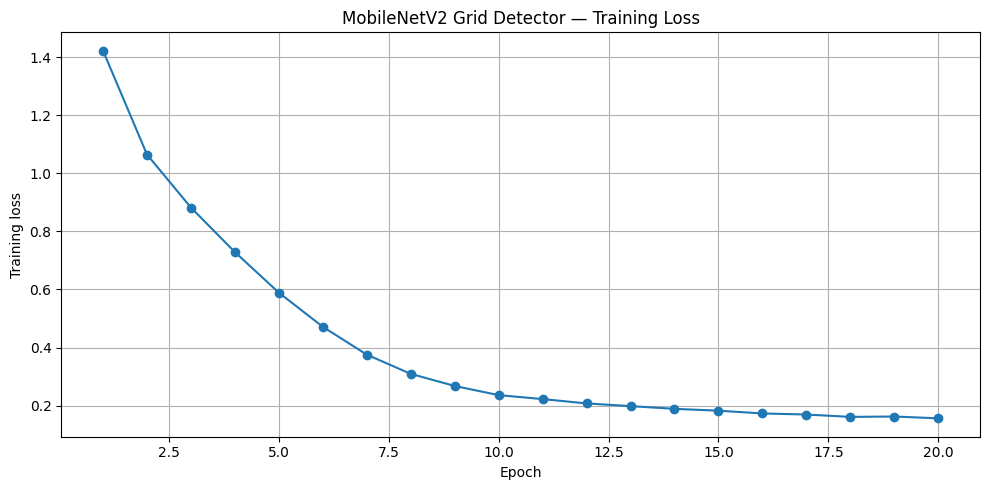

Training history: /workspace/ITS_Project/results/training/mobilenetv2/training_history.csv
Training curve: /workspace/ITS_Project/results/training/mobilenetv2/training_loss.png


In [13]:
# CELL 14: Plot and save training-loss curve

history_path = RESULT_DIR / "training_history.csv"

if history_path.is_file():
    history_df = pd.read_csv(history_path)
else:
    history_df = pd.DataFrame(history_records)

display(history_df.tail())

if not history_df.empty:
    plt.figure(figsize=(10, 5))
    plt.plot(history_df["epoch"], history_df["train_loss"], marker="o")
    plt.xlabel("Epoch")
    plt.ylabel("Training loss")
    plt.title("MobileNetV2 Grid Detector — Training Loss")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(RESULT_DIR / "training_loss.png", dpi=150)
    plt.show()

print("Training history:", history_path)
print("Training curve:", RESULT_DIR / "training_loss.png")

frontFar__BLR-2018-04-16_16-14-27_frontFar__0000060.jpg: 1 predicted boxes


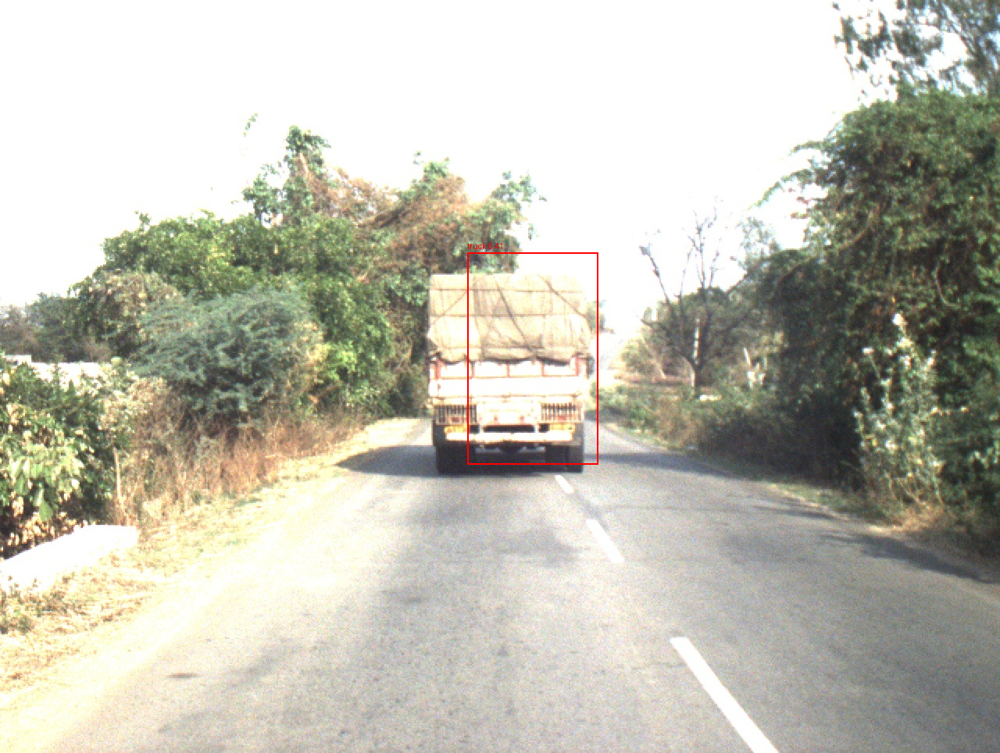

frontFar__BLR-2018-04-16_16-14-27_frontFar__000006_r.jpg: 1 predicted boxes


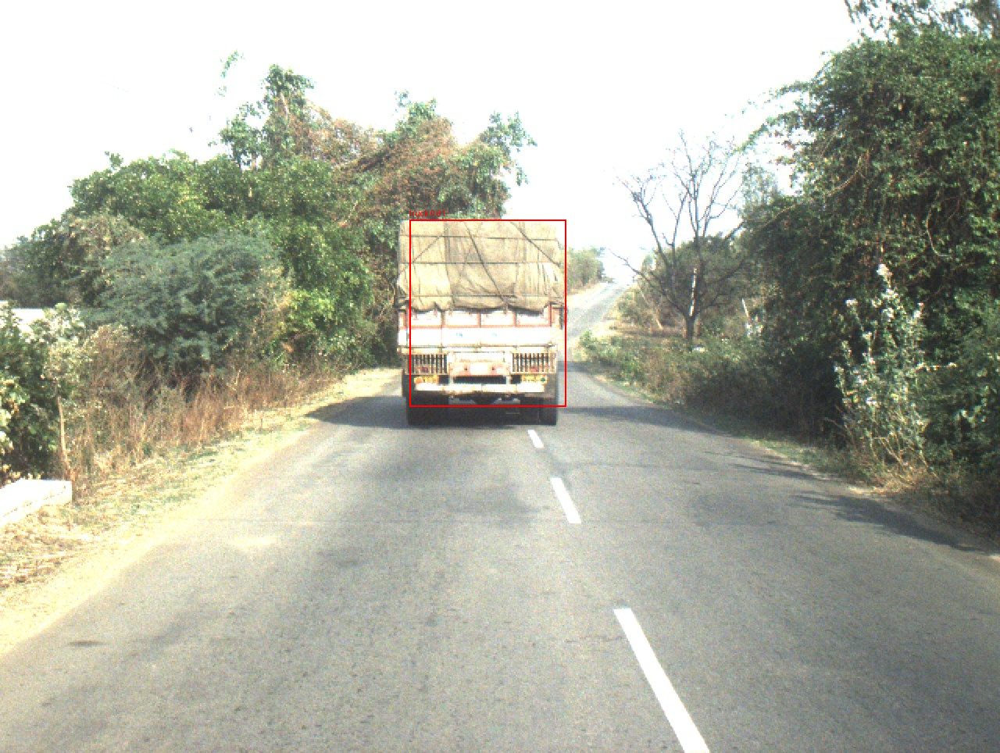

frontFar__BLR-2018-04-16_16-14-27_frontFar__0000120.jpg: 1 predicted boxes


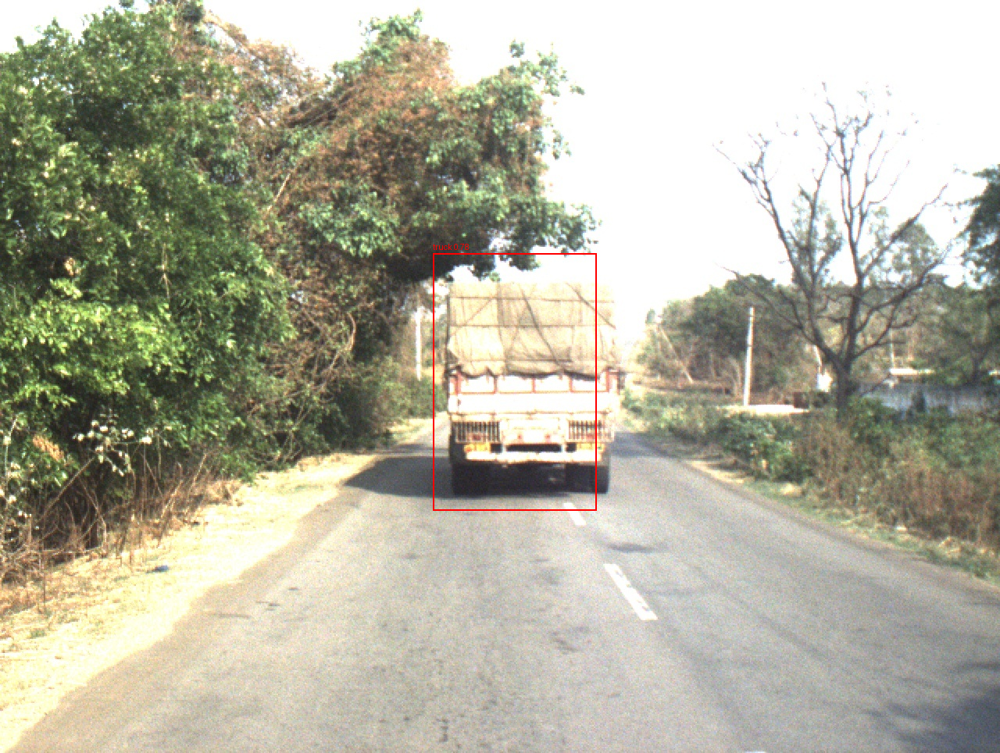

frontFar__BLR-2018-04-16_16-14-27_frontFar__000012_r.jpg: 2 predicted boxes


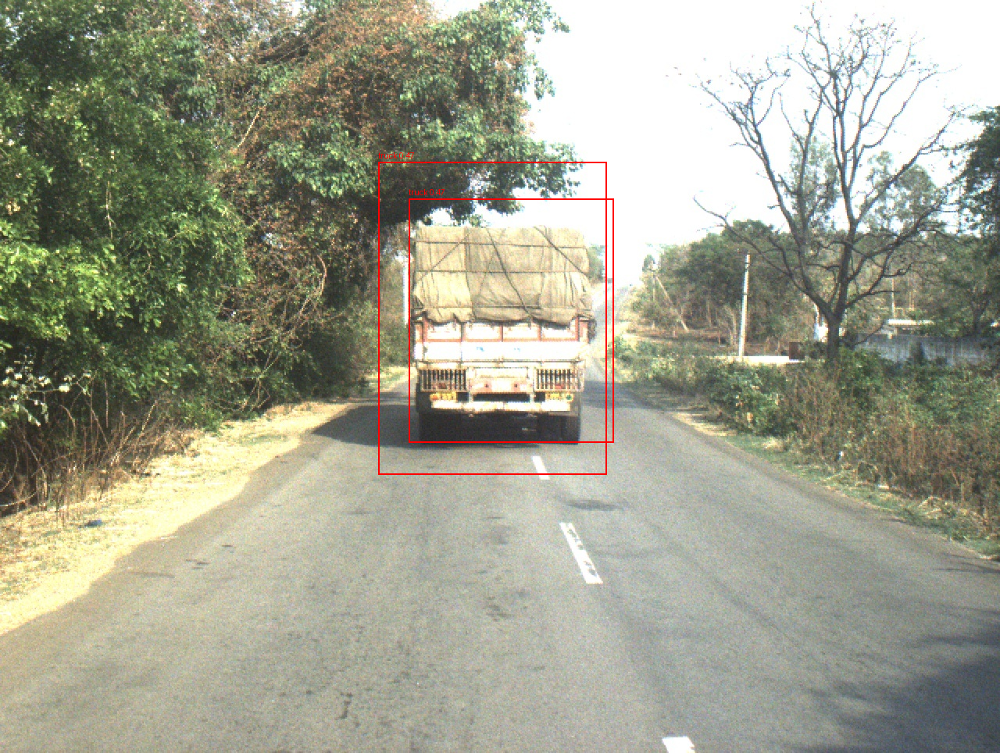

frontFar__BLR-2018-04-16_16-14-27_frontFar__0000180.jpg: 1 predicted boxes


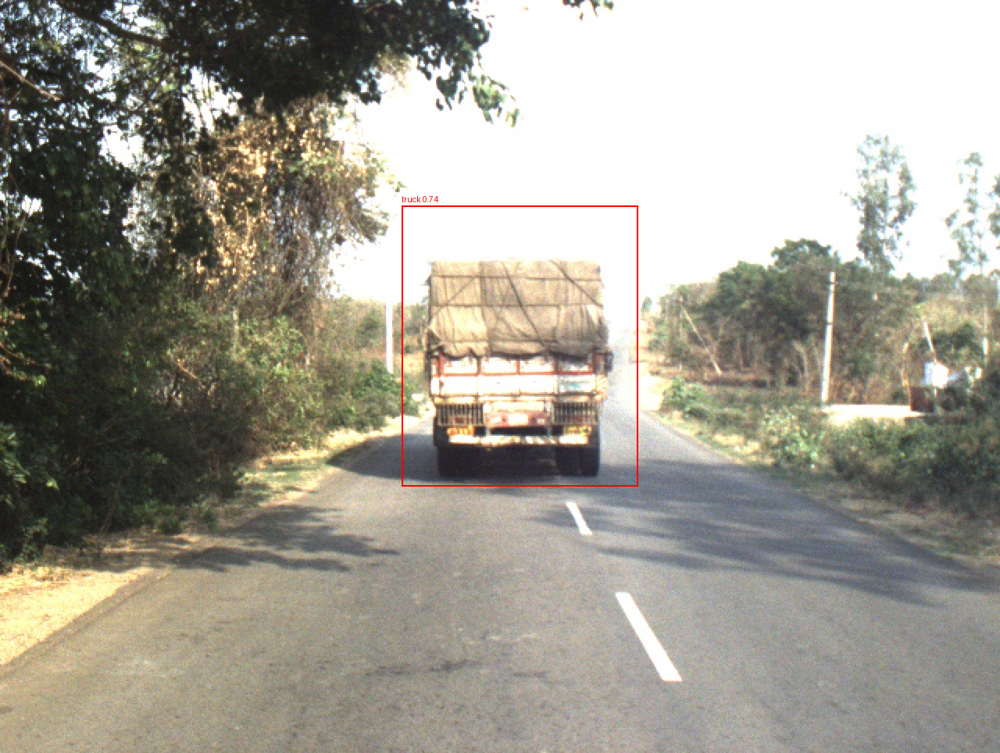

frontFar__BLR-2018-04-16_16-14-27_frontFar__000018_r.jpg: 1 predicted boxes


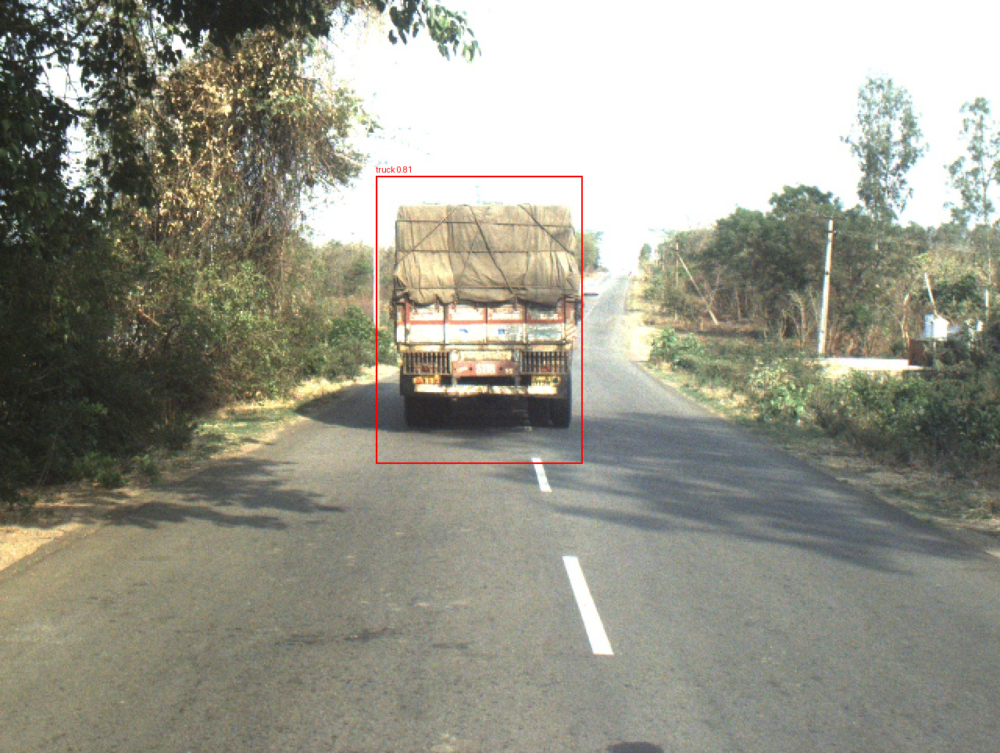

Notebook 08 cells completed.
Note: these predictions and losses do not establish detection mAP.


In [14]:
# CELL 15: Decode grid predictions and visualize sample validation images

def decode_grid_predictions(prediction, image_width, image_height, threshold=0.25):
    prediction = prediction.detach().cpu()
    results = []

    objectness = torch.sigmoid(prediction[..., 0])
    boxes = torch.sigmoid(prediction[..., 1:5])
    class_probs = torch.softmax(prediction[..., 5:], dim=-1)

    for gy in range(GRID_SIZE):
        for gx in range(GRID_SIZE):
            confidence = float(objectness[gy, gx])
            if confidence < threshold:
                continue

            class_confidence, class_id = class_probs[gy, gx].max(dim=-1)
            score = confidence * float(class_confidence)

            x_offset, y_offset, bw, bh = boxes[gy, gx].tolist()
            xc = (gx + x_offset) / GRID_SIZE
            yc = (gy + y_offset) / GRID_SIZE

            x1 = max(0, int((xc - bw / 2) * image_width))
            y1 = max(0, int((yc - bh / 2) * image_height))
            x2 = min(image_width - 1, int((xc + bw / 2) * image_width))
            y2 = min(image_height - 1, int((yc + bh / 2) * image_height))

            if x2 > x1 and y2 > y1:
                results.append((x1, y1, x2, y2, int(class_id), score))

    return results


detector.eval()
sample_paths = sorted(VAL_IMAGE_DIR.glob("*.jpg"))[:6]

for image_path in sample_paths:
    original = Image.open(image_path).convert("RGB")
    width, height = original.size
    input_tensor = val_transform(original).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        output = detector(input_tensor)[0]

    boxes = decode_grid_predictions(output, width, height, threshold=0.25)
    visual = original.copy()
    draw = ImageDraw.Draw(visual)

    for x1, y1, x2, y2, class_id, score in boxes:
        label = CLASS_NAMES.get(class_id, str(class_id))
        draw.rectangle((x1, y1, x2, y2), outline="red", width=2)
        draw.text((x1, max(0, y1 - 14)), f"{label} {score:.2f}", fill="red")

    print(f"{image_path.name}: {len(boxes)} predicted boxes")
    display(visual)

print("Notebook 08 cells completed.")
print("Note: these predictions and losses do not establish detection mAP.")

In [15]:
# CELL 16: Evaluate MobileNetV2 precision and recall at IoU 0.50

from collections import defaultdict

def box_iou_xyxy(boxes1, boxes2):
    if len(boxes1) == 0 or len(boxes2) == 0:
        return torch.zeros((len(boxes1), len(boxes2)))

    a = torch.tensor(boxes1, dtype=torch.float32)
    b = torch.tensor(boxes2, dtype=torch.float32)

    left_top = torch.maximum(a[:, None, :2], b[None, :, :2])
    right_bottom = torch.minimum(a[:, None, 2:], b[None, :, 2:])
    intersection = (
        (right_bottom - left_top).clamp(min=0).prod(dim=2)
    )

    area_a = (a[:, 2] - a[:, 0]).clamp(min=0) * (
        a[:, 3] - a[:, 1]
    ).clamp(min=0)

    area_b = (b[:, 2] - b[:, 0]).clamp(min=0) * (
        b[:, 3] - b[:, 1]
    ).clamp(min=0)

    union = area_a[:, None] + area_b[None, :] - intersection
    return intersection / union.clamp(min=1e-9)


detector.eval()
tp = 0
fp = 0
fn = 0

with torch.no_grad():
    for images, targets in tqdm(val_loader, desc="Detection evaluation"):
        images = images.to(DEVICE)
        outputs = detector(images)

        for output, target in zip(outputs, targets):
            original_height, original_width = target["original_size"].tolist()

            predictions = decode_grid_predictions(
                output,
                original_width,
                original_height,
                threshold=0.25,
            )

            # Apply class-aware matching at IoU >= 0.50.
            pred_boxes = [p[:4] for p in predictions]
            pred_classes = [p[4] for p in predictions]
            gt_boxes = target["boxes"].tolist()
            gt_classes = target["labels"].tolist()

            matched_gt = set()

            # Highest-confidence predictions first.
            predictions_sorted = sorted(
                range(len(predictions)),
                key=lambda i: predictions[i][5],
                reverse=True,
            )

            for pi in predictions_sorted:
                same_class_gt = [
                    gi for gi, cls in enumerate(gt_classes)
                    if cls == pred_classes[pi] and gi not in matched_gt
                ]

                if not same_class_gt:
                    fp += 1
                    continue

                ious = box_iou_xyxy(
                    [pred_boxes[pi]],
                    [gt_boxes[gi] for gi in same_class_gt],
                )[0]

                best_position = int(ious.argmax())
                best_iou = float(ious[best_position])

                if best_iou >= 0.50:
                    tp += 1
                    matched_gt.add(same_class_gt[best_position])
                else:
                    fp += 1

            fn += len(gt_boxes) - len(matched_gt)

precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0

print("True positives:", tp)
print("False positives:", fp)
print("False negatives:", fn)
print(f"Precision @ IoU 0.50: {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall @ IoU 0.50: {recall:.4f} ({recall * 100:.2f}%)")

Detection evaluation:   0%|          | 0/320 [00:00<?, ?it/s]

True positives: 15302
False positives: 44426
False negatives: 110757
Precision @ IoU 0.50: 0.2562 (25.62%)
Recall @ IoU 0.50: 0.1214 (12.14%)


In [19]:
# CELL 17: Save MobileNetV2 detection metrics

metrics_path = RESULT_DIR / "validation_metrics.json"

with open(metrics_path, "r") as f:
    saved_metrics = json.load(f)

saved_metrics.update({
    "precision": float(precision),
    "recall": float(recall),
    "iou_threshold": 0.50,
    "true_positives": int(tp),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "mAP50": None,
    "mAP50_95": None,
    "metric_note": (
        "Precision and recall calculated using class-aware greedy matching "
        "at IoU 0.50. mAP not calculated."
    ),
})

with open(metrics_path, "w") as f:
    json.dump(saved_metrics, f, indent=2)

print("Saved updated metrics:", metrics_path)
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print("mAP remains unavailable.")

Saved updated metrics: /workspace/ITS_Project/results/training/mobilenetv2/validation_metrics.json
Precision: 25.62%
Recall: 12.14%
mAP remains unavailable.
